## **Fase 00 - Explicação Conceitual Teórica**

Explicação do processo de algoritmo evolucionário aplicado as mecânicas do jogo **Flappy Bird** em detalhes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import pandas as pd

# Estilo dos gráficos
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

np.random.seed(42)
print("Setup concluído.")

Setup concluído.


# Matemática da Computação Evolucionária aplicada ao Flappy Bird

> **Documento didático — Fase Zero**
> Tema 3: Algoritmos Genéticos (GA) aplicados ao controle autônomo de um agente no jogo Flappy Bird

---

## Sumário

- **PARTE A — FUNDAMENTOS**
  - A.1 O que é um Algoritmo Genético
  - A.2 Analogia com evolução biológica
  - A.3 O que é um vetor
  - A.4 Número aleatório uniforme $U(0,1)$
  - A.5 Distribuição normal $\mathcal{N}(0,\sigma^2)$
  - A.6 Somatório $\sum$
  - A.7 Função de ativação

- **PARTE B — REPRESENTAÇÃO DO PÁSSARO**
  - B.1 Genoma (vetor de 6 genes)
  - B.2 Entradas sensoriais + normalização
  - B.3 Soma ponderada $z$
  - B.4 Sigmoide
  - B.5 Regra de decisão
  - B.6 Exemplo completo

- **PARTE C — FÍSICA DO JOGO**
- **PARTE D — FITNESS**
- **PARTE E — MORTE E SELEÇÃO**
- **PARTE F — CRUZAMENTO**
- **PARTE G — MUTAÇÃO**
- **PARTE H — NOVA GERAÇÃO**
- **PARTE I — CICLO COMPLETO**
- **PARTE J — GLOSSÁRIO**

# PARTE A — FUNDAMENTOS

Nesta parte não falamos de Flappy Bird ainda. Aqui construímos o alicerce: os conceitos e a notação que serão usados no resto do documento. Se você pular esta parte, o resto não vai fazer sentido.

---

## A.1 O que é um Algoritmo Genético, em linguagem de leigo

**Em termos simples:** um Algoritmo Genético (GA) é uma forma de resolver problemas por tentativa e erro organizada, imitando como a natureza faz para melhorar espécies ao longo de gerações.

Imagine que você precisa descobrir uma combinação de números (uma "receita") que faça um robô jogar bem um jogo. Você não sabe quais números usar. Poderia testar todas as combinações possíveis, mas o número de combinações é astronômico — levaria séculos. Em vez disso, você faz o seguinte:

1. Cria 50 receitas aleatórias.
2. Testa todas no jogo e dá uma nota para cada uma (nota alta = jogou bem).
3. As receitas com nota alta têm mais chance de "se reproduzir": você pega pedaços de duas boas receitas e monta uma receita nova.
4. Adiciona pequenos erros aleatórios nas receitas novas (para não ficarem todas iguais).
5. Descarta as receitas ruins e repete com as novas.

Depois de dezenas de repetições, as receitas ficam cada vez melhores — não porque você programou a solução, mas porque o processo de seleção + reprodução + erro foi empurrando a população na direção certa.

**Por que isso funciona?** Porque em quase todo problema existe uma "paisagem" onde soluções parecidas tendem a ter desempenho parecido. Se você pega duas soluções boas e mistura, frequentemente a mistura também é boa. E pequenas perturbações ocasionalmente descobrem um "degrau" ainda mais alto.

**Efeito prático:**
- Se você **aumentar** o número de indivíduos por geração, o algoritmo fica mais lento mas mais robusto.
- Se você **diminuir**, fica mais rápido mas pode não encontrar boas soluções.

**Resumo da seção:** Algoritmo Genético é resolver problemas por tentativa organizada, imitando evolução: cria população aleatória → avalia → seleciona melhores → reproduz com mistura → muta → repete. Não programamos a solução; deixamos ela emergir.

## A.2 Analogia com evolução biológica

**Em termos simples:** cada termo técnico do GA tem um correspondente na biologia. Entender essa correspondência é a chave para não se perder.

| Termo no GA | Correspondente biológico | O que significa no nosso Flappy Bird |
|-------------|--------------------------|--------------------------------------|
| **Gene** | Um trecho de DNA | Um número real (ex.: `0.31`) |
| **Genoma** (ou indivíduo) | O DNA completo de um ser vivo | Um vetor de 6 números |
| **População** | O conjunto de seres vivos de uma espécie | 50 pássaros simultâneos |
| **Geração** | Uma "rodada" de vida | Um ciclo completo: avaliar → reproduzir |
| **Fitness** (aptidão) | Quão bem o ser vivo sobrevive | Pontuação obtida no jogo |
| **Seleção natural** | Quem sobrevive para reproduzir | Escolhemos os de maior fitness como pais |
| **Cruzamento** (crossover) | Reprodução sexuada | Misturamos os genes de dois pais |
| **Mutação** | Erro na cópia do DNA | Perturbamos aleatoriamente um gene |
| **Elitismo** | Os mais fortes sempre sobrevivem | Copiamos os melhores intactos para a próxima geração |

**Como isso se lê na prática:** a natureza não "sabe" qual é o melhor DNA. Ela apenas faz com que os indivíduos mais bem adaptados tenham mais filhos. Os filhos herdam metade do DNA de cada pai, e erros de cópia ocasionais geram novidade. Ao longo de milhões de anos, isso produz olhos, asas, cérebros. No nosso caso, "milhões de anos" viram "dezenas de gerações de computador" — o princípio é o mesmo.

**Efeito prático:**
- **Sem cruzamento**, cada indivíduo só pode melhorar por mutação: evolução lenta.
- **Sem mutação**, todos os filhos ficam iguais aos pais: a evolução estagnaria em poucas gerações.
- **Sem seleção**, todos se reproduzem igualmente: não há pressão para melhorar.

**Resumo da seção:** Todo termo do GA tem gêmeo biológico. Gene é número, genoma é vetor, população é conjunto de pássaros, fitness é nota, seleção é escolher pais, cruzamento é reprodução, mutação é erro de cópia, elitismo é garantir que o melhor nunca morra. Os três pilares que fazem a evolução andar são: seleção, cruzamento e mutação — sem qualquer um deles, o algoritmo não funciona bem.

## A.3 O que é um vetor (matriz de uma linha) — do zero

**Em termos simples:** um vetor é uma lista ordenada de números. Nada mais que isso.

Quando escrevemos:

$$
v = [3, 7, 1]
$$

Estamos dizendo: "tenho três números, na ordem 3, 7, 1". O primeiro é o "gene 1", o segundo é o "gene 2", o terceiro é o "gene 3". A posição na lista importa: `[3, 7, 1]` é diferente de `[1, 7, 3]`.

### Notação

Para nos referirmos a **um** elemento do vetor, usamos índice entre colchetes:

- $v[1] = 3$ (primeiro elemento)
- $v[2] = 7$ (segundo elemento)
- $v[3] = 1$ (terceiro elemento)

> **Atenção a uma pegadinha:** em matemática, geralmente indexamos a partir de 1. Em programação (JavaScript, Python, etc.), indexamos a partir de 0. Neste documento, para ficar alinhado com a matemática tradicional, uso índice começando em 1. Na hora de implementar (Fase 1), você adaptará para começar em 0.

### Tamanho do vetor

Chamamos de **tamanho** ou **dimensão** o número de elementos. O vetor `[3, 7, 1]` tem tamanho 3.

No nosso Flappy Bird, o genoma de cada pássaro é um vetor de tamanho **6**:

$$
g = [w_1, w_2, w_3, w_4, w_5, b]
$$

### Exemplo numérico — Seção A.3

**Entrada:** $g = [0.3, -1.2, 0.8, 0.5, -0.1, 0.2]$

**Passo 1:** contar elementos → 6

**Passo 2:** $g[1] = 0.3$, $g[2] = -1.2$, $g[3] = 0.8$

**Passo 3:** $g[4] = 0.5$, $g[5] = -0.1$, $g[6] = 0.2$

**Resultado:** vetor de dimensão 6.

**Se $g[3]$ fosse $1.5$ em vez de $0.8$:** o vetor seria $[0.3, -1.2, 1.5, 0.5, -0.1, 0.2]$, com mesmo tamanho, mas o terceiro elemento diferente.

**Efeito prático:**
- **Aumentar** o tamanho do vetor = mais informação por indivíduo = mais liberdade de decisão, mas mais difícil de evoluir.
- **Diminuir** = indivíduo mais "burro", mas mais fácil de evoluir.

**Resumo da seção:** Vetor é lista ordenada de números. Acessamos cada elemento por índice. Nosso genoma é um vetor de 6 números. Tamanho do vetor é quantos elementos ele tem.

## A.4 O que é um número aleatório uniforme $U(0,1)$ — do zero

**Em termos simples:** é um número sorteado ao acaso entre 0 e 1, onde **qualquer valor tem a mesma chance** de sair.

### A notação

Quando escrevemos:

$$
u \sim U(0,1)
$$

Estamos dizendo: "$u$ é um número sorteado de uma distribuição **U**niforme entre **0** e **1**". O símbolo $\sim$ lê-se "tem distribuição".

- $U$ vem de **Uniforme**
- $(0, 1)$ significa "entre 0 e 1"

### O que "uniforme" quer dizer

Numa distribuição uniforme, a probabilidade de cair em qualquer subintervalo do mesmo tamanho é igual. Exemplos:

- Probabilidade de cair entre 0 e 0.1 = 10%
- Probabilidade de cair entre 0.5 e 0.6 = 10%
- Probabilidade de cair entre 0.9 e 1.0 = 10%

O gráfico da densidade de probabilidade em função do valor é uma **linha reta horizontal** (uma "caixa"). Execute a célula de código a seguir para visualizar.

### Como sortear na prática

Em qualquer linguagem, existe uma função que devolve exatamente isso. Em JavaScript é `Math.random()`. Ela pode devolver `0.0001234`, `0.7823`, `0.999...`, todos com mesma chance.

### Onde usamos $U(0,1)$ no GA

- **Inicialização:** sortear os genes iniciais da população
- **Cruzamento uniforme:** decidir de qual pai vem cada gene
- **Torneio:** sortear quais indivíduos entram no torneio
- **Mutação:** sortear se um gene vai mutar
- **Taxa de cruzamento:** sortear se um par cruza

Praticamente todo passo do GA usa pelo menos um sorteio uniforme.

### Exemplo numérico — Seção A.4

**Entrada:** nenhuma (é um sorteio)

**Passo 1:** chamar a função de sorteio → retorna $0.7234$

**Passo 2:** como $0.7234 \in [0,1]$, é válido

**Passo 3:** chamar de novo → retorna $0.0521$

**Resultado:** dois valores sorteados: $u_1 = 0.7234$, $u_2 = 0.0521$.

**Se a função retornasse $1.5$:** seria inválido (fora de $[0,1]$). **Se retornasse $-0.3$:** também inválido.

**Efeito prático:**
- Se você sortear muitos valores $U(0,1)$ e tirar a média, ela se aproxima de **0.5**.
- Se você sortear 100 valores e contar quantos são menores que 0.3, aproximadamente **30** serão.

**Resumo da seção:** $U(0,1)$ é um sorteio uniforme entre 0 e 1. Todos os valores têm a mesma chance. Usamos em todos os passos do GA para tomar decisões aleatórias controladas.

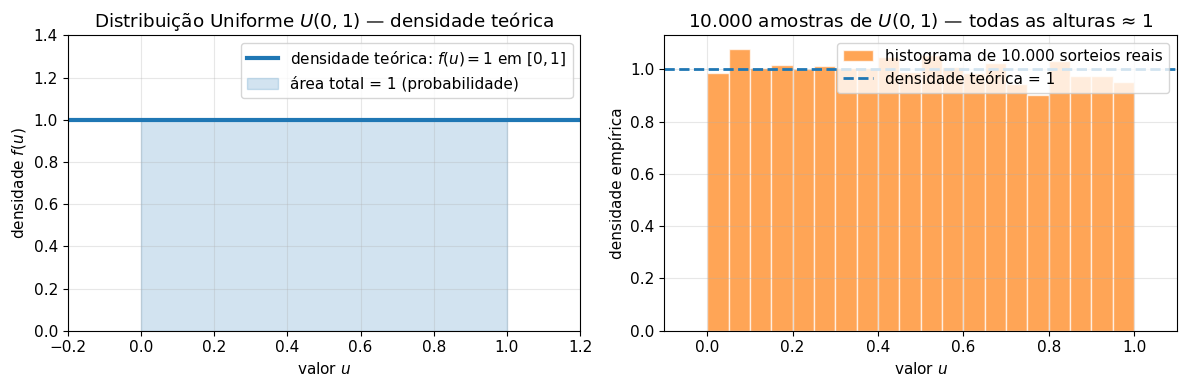

Média amostral:  0.4942  (esperado: 0.5000)
Desvio-padrão:   0.2876   (esperado: 0.2887)
Frequência de u < 0.3: 0.305  (esperado: 0.300)
Frequência de u < 0.7: 0.711  (esperado: 0.700)


In [4]:
# Gráfico da densidade uniforme U(0,1) vs. histograma de amostras reais
np.random.seed(42)
amostras = np.random.uniform(0, 1, 10000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# (1) Densidade teórica: retângulo de altura 1 em [0,1]
ax1.axhline(1.0, xmin=0, xmax=1, color='#1f77b4', linewidth=3,
            label=r'densidade teórica: $f(u)=1$ em $[0,1]$')
ax1.fill_between([0, 1], [1, 1], alpha=0.2, color='#1f77b4',
                 label='área total = 1 (probabilidade)')
ax1.set_xlim(-0.2, 1.2)
ax1.set_ylim(0, 1.4)
ax1.set_xlabel('valor $u$')
ax1.set_ylabel('densidade $f(u)$')
ax1.set_title(r'Distribuição Uniforme $U(0,1)$ — densidade teórica')
ax1.legend(loc='upper right')

# (2) Histograma de 10000 amostras reais
ax2.hist(amostras, bins=20, density=True, alpha=0.7,
         color='#ff7f0e', edgecolor='white',
         label='histograma de 10.000 sorteios reais')
ax2.axhline(1.0, color='#1f77b4', linewidth=2, linestyle='--',
            label='densidade teórica = 1')
ax2.set_xlim(-0.1, 1.1)
ax2.set_xlabel('valor $u$')
ax2.set_ylabel('densidade empírica')
ax2.set_title(r'10.000 amostras de $U(0,1)$ — todas as alturas ≈ 1')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

# Estatísticas descritivas que confirmam o comportamento uniforme
print(f"Média amostral:  {amostras.mean():.4f}  (esperado: 0.5000)")
print(f"Desvio-padrão:   {amostras.std():.4f}   (esperado: {1/np.sqrt(12):.4f})")
print(f"Frequência de u < 0.3: {np.mean(amostras < 0.3):.3f}  (esperado: 0.300)")
print(f"Frequência de u < 0.7: {np.mean(amostras < 0.7):.3f}  (esperado: 0.700)")

## A.5 O que é uma distribuição normal $\mathcal{N}(0,\sigma^2)$ — do zero

**Em termos simples:** é um sorteio de número ao acaso, mas **não uniforme**: valores próximos da média são muito mais prováveis do que valores distantes. É a famosa "curva do sino".

### A notação

Quando escrevemos:

$$
\Delta \sim \mathcal{N}(0, \sigma^2)
$$

Estamos dizendo: "$\Delta$ (delta) é um número sorteado de uma distribuição **N**ormal com **média 0** e **variância** $\sigma^2$". O símbolo $\mathcal{N}$ vem de "Normal".

- **Média = 0:** o valor em torno do qual os sorteios se concentram é 0.
- **Variância = $\sigma^2$:** o quadrado do desvio-padrão $\sigma$. Controla o "espalhamento".

### O que é desvio-padrão $\sigma$

$\sigma$ é a letra grega **sigma**. Ela mede o quanto os valores se afastam da média em média.

- $\sigma$ **pequeno** → curva **estreita e alta** → valores quase sempre perto de 0
- $\sigma$ **grande** → curva **larga e baixa** → valores podem se afastar mais de 0

Execute a célula de código a seguir para **ver** essa diferença num gráfico real.

### A regra 68-95-99.7

Para qualquer distribuição normal:

- ~68% dos sorteios caem entre $-\sigma$ e $+\sigma$
- ~95% caem entre $-2\sigma$ e $+2\sigma$
- ~99.7% caem entre $-3\sigma$ e $+3\sigma$

Isso significa que, se $\sigma = 0.3$, valores como $+0.1$, $-0.2$, $0.05$ são muito comuns, mas $+1.5$ é raro, e $+3.0$ é quase impossível.

### Por que usamos normal na mutação

Queremos que mutações sejam geralmente **pequenas** (refinar) mas ocasionalmente **médias** (explorar). A curva gaussiana faz exatamente isso: alta probabilidade para perturbações pequenas, baixa para perturbações grandes.

### Como sortear na prática

Em JavaScript não existe função nativa para distribuição normal, mas há várias formas de simular (ex.: transformação de Box-Muller). Não precisamos nos preocupar agora com isso — ficará para a Fase 1.

### Exemplo numérico — Seção A.5

**Entrada:** $\sigma = 0.3$

**Passo 1:** 3 sorteios → $\Delta_1 = 0.12$, $\Delta_2 = -0.31$, $\Delta_3 = 0.08$

**Passo 2:** todos os três estão entre $-0.3$ e $0.3$ (dentro de $\pm 1\sigma$), o esperado em ~68% das vezes

**Resultado:** valores típicos: pequenas perturbações.

**Se $\sigma$ fosse $2.0$ em vez de $0.3$:** os mesmos sorteios poderiam ser $\Delta_1 = 0.8$, $\Delta_2 = -2.1$, $\Delta_3 = 0.5$ — perturbações muito maiores.

**Efeito prático:**
- **Aumentar $\sigma$** → mutações maiores, mais exploração, menos refinamento (o algoritmo "pula" mais).
- **Diminuir $\sigma$** → mutações finas, mais refinamento, menos exploração.

**Resumo da seção:** $\mathcal{N}(0,\sigma^2)$ é a curva do sino. Sorteia valores concentrados perto de zero. $\sigma$ controla o espalhamento. Usamos na mutação para pequenas perturbações serem comuns e grandes serem raras.

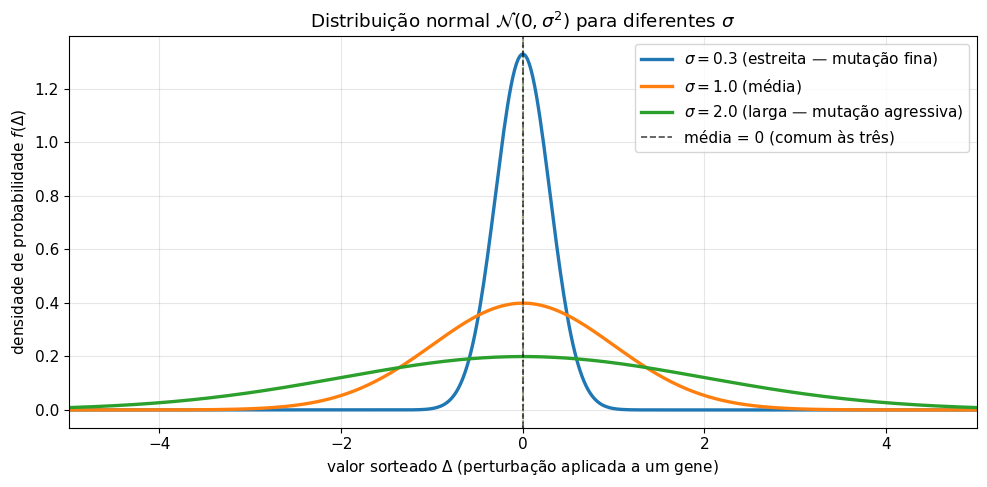

Altura do pico (densidade em Δ=0) para cada σ:
  σ = 0.3  →  pico = 1.330  |  P(|Δ| ≤ 1σ) = 68.3%
  σ = 1.0  →  pico = 0.399  |  P(|Δ| ≤ 1σ) = 68.3%
  σ = 2.0  →  pico = 0.199  |  P(|Δ| ≤ 1σ) = 68.3%


In [5]:
# Comparação de três distribuições normais com σ diferentes
x = np.linspace(-5, 5, 500)

fig, ax = plt.subplots(figsize=(10, 5))

configs = [
    (0.3, '#1f77b4', r'$\sigma = 0.3$ (estreita — mutação fina)'),
    (1.0, '#ff7f0e', r'$\sigma = 1.0$ (média)'),
    (2.0, '#2ca02c', r'$\sigma = 2.0$ (larga — mutação agressiva)'),
]

for sigma, cor, label in configs:
    ax.plot(x, norm.pdf(x, 0, sigma), linewidth=2.4, color=cor, label=label)
    # linha vertical no pico (média = 0) com a altura correspondente
    ax.axvline(0, color=cor, linestyle=':', alpha=0.35)

ax.axvline(0, color='black', linestyle='--', alpha=0.7, linewidth=1.2,
           label='média = 0 (comum às três)')

ax.set_title(r'Distribuição normal $\mathcal{N}(0,\sigma^2)$ para diferentes $\sigma$')
ax.set_xlabel(r'valor sorteado $\Delta$ (perturbação aplicada a um gene)')
ax.set_ylabel('densidade de probabilidade $f(\Delta)$')
ax.legend(loc='upper right')
ax.set_xlim(-5, 5)

plt.tight_layout()
plt.show()

# Estatística numérica para complementar o gráfico
print("Altura do pico (densidade em Δ=0) para cada σ:")
for sigma, _, _ in configs:
    pico = norm.pdf(0, 0, sigma)
    frac_1sigma = norm.cdf(sigma, 0, sigma) - norm.cdf(-sigma, 0, sigma)
    print(f"  σ = {sigma:.1f}  →  pico = {pico:.3f}  |  "
          f"P(|Δ| ≤ 1σ) = {frac_1sigma:.1%}")

### A regra 68-95-99.7 — visualização

A regra 68-95-99.7 é uma propriedade **universal** de qualquer distribuição normal: independente do valor de $\sigma$ e da média, a proporção de amostras dentro de $k$ desvios-padrão é sempre a mesma.

| Intervalo | Proporção de sorteios | Interpretação prática com $\sigma = 0.3$ |
|-----------|----------------------|-------------------------------------------|
| $[\mu-\sigma, \mu+\sigma]$ | ~68% | ~68% das mutações ficam entre $-0.3$ e $+0.3$ |
| $[\mu-2\sigma, \mu+2\sigma]$ | ~95% | ~95% das mutações ficam entre $-0.6$ e $+0.6$ |
| $[\mu-3\sigma, \mu+3\sigma]$ | ~99.7% | ~99.7% das mutações ficam entre $-0.9$ e $+0.9$ |

**Consequência importante para o GA:** se você escolhe $\sigma = 0.3$, então mutações "gigantes" (por exemplo, um gene saltando de $0.5$ para $1.5$) são **extremamente raras** — só acontecem 0.3% das vezes. Isso é bom: o gene não muda radicalmente por acaso, apenas refina.

**Por outro lado,** se você **quiser** exploração agressiva (saltos grandes ocasionais para descobrir regiões novas do espaço de busca), precisa **aumentar** $\sigma$. Com $\sigma = 1.0$, um salto de $+1.5$ já é bem mais provável (~13% dos casos).

**Regra mnemônica:** $\sigma$ pequeno = evolução **conservadora**; $\sigma$ grande = evolução **aventureira**.

**Resumo da seção:** A regra 68-95-99.7 diz que, em qualquer normal, 68% dos valores ficam dentro de $\pm 1\sigma$, 95% dentro de $\pm 2\sigma$ e 99.7% dentro de $\pm 3\sigma$. Isso nos permite raciocinar sobre a "personalidade" da mutação: quanto menor o $\sigma$, mais conservadora é a perturbação.

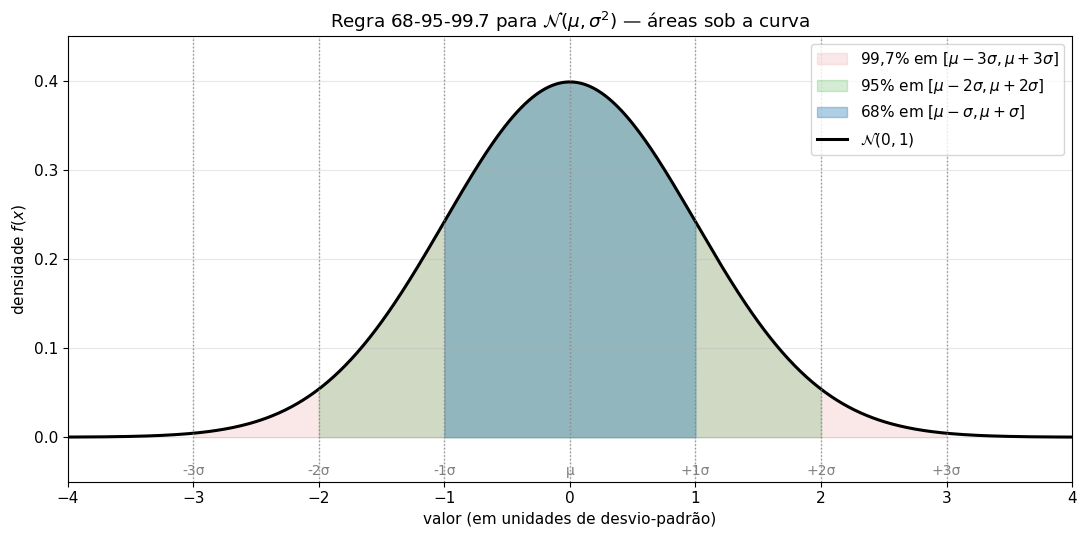

Verificação numérica exata para N(0,1):
  P(|X| ≤ 1σ) =  68.27%  (esperado ≈ 68.27%)
  P(|X| ≤ 2σ) =  95.45%  (esperado ≈ 95.45%)
  P(|X| ≤ 3σ) =  99.73%  (esperado ≈ 99.73%)

Para σ = 0.3, em termos absolutos:
  P(Δ ∈ [-0.30, +0.30]) =  68.27%
  P(Δ ∈ [-0.60, +0.60]) =  95.45%
  P(Δ ∈ [-0.90, +0.90]) =  99.73%


In [6]:
# Ilustração das áreas sob a curva normal padrão N(0,1)
x = np.linspace(-4, 4, 500)
y = norm.pdf(x, 0, 1)

fig, ax = plt.subplots(figsize=(11, 5.5))

# Camadas de área, do mais largo para o mais estreito (para empilhamento visual correto)
camadas = [
    (-3, 3, '#d62728', 0.10, r'$99{,}7\%$ em $[\mu - 3\sigma, \mu + 3\sigma]$'),
    (-2, 2, '#2ca02c', 0.20, r'$95\%$ em $[\mu - 2\sigma, \mu + 2\sigma]$'),
    (-1, 1, '#1f77b4', 0.35, r'$68\%$ em $[\mu - \sigma, \mu + \sigma]$'),
]

for lo, hi, cor, alpha, rotulo in camadas:
    xs = np.linspace(lo, hi, 300)
    ax.fill_between(xs, norm.pdf(xs, 0, 1), alpha=alpha, color=cor, label=rotulo)

# Curva por cima das áreas
ax.plot(x, y, color='black', linewidth=2.2, label=r'$\mathcal{N}(0,1)$')

# Marcações dos desvios-padrão
for k in [-3, -2, -1, 0, 1, 2, 3]:
    ax.axvline(k, color='gray', linestyle=':', linewidth=1, alpha=0.8)
    ax.text(k, -0.03, f'{k:+d}σ' if k != 0 else 'μ',
            ha='center', va='top', fontsize=10, color='gray')

ax.set_title(r'Regra 68-95-99.7 para $\mathcal{N}(\mu,\sigma^2)$ — áreas sob a curva')
ax.set_xlabel('valor (em unidades de desvio-padrão)')
ax.set_ylabel('densidade $f(x)$')
ax.set_xlim(-4, 4)
ax.set_ylim(-0.05, 0.45)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Verificação numérica exata (deve bater com 68-95-99.7)
print("Verificação numérica exata para N(0,1):")
for k, esperado in [(1, 68.27), (2, 95.45), (3, 99.73)]:
    real = (norm.cdf(k, 0, 1) - norm.cdf(-k, 0, 1)) * 100
    print(f"  P(|X| ≤ {k}σ) = {real:6.2f}%  (esperado ≈ {esperado:.2f}%)")

print("\nPara σ = 0.3, em termos absolutos:")
for k in [1, 2, 3]:
    lo, hi = -k * 0.3, k * 0.3
    real = (norm.cdf(hi, 0, 0.3) - norm.cdf(lo, 0, 0.3)) * 100
    print(f"  P(Δ ∈ [{lo:+.2f}, {hi:+.2f}]) = {real:6.2f}%")